In [60]:
import os
import random
import time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn pour le preprocessing et les métriques
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.metrics import f1_score, precision_score, recall_score, confusion_matrix, classification_report
import joblib  # Pour sauvegarder les scalers

# 1. Configuration de la Reproductibilité (State-of-the-Art Practice)
SEED = 42

def set_seed(seed=42):
    """Fixe les graines aléatoires pour garantir la reproductibilité totale des résultats."""
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Pour des convolutions déterministes (peut ralentir légèrement mais essentiel pour la science)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"[INFO] Global Seed set to {seed}")

# 2. Gestion de l'environnement et des dossiers
def setup_env():
    """Crée l'arborescence nécessaire si elle n'existe pas."""
    directories = ['datasets', 'models']
    for d in directories:
        os.makedirs(d, exist_ok=True)
        print(f"[INFO] Dossier vérifié/créé : {d}/")
    
    # Vérification du dossier Input (Juste un warning si absent, car c'est l'utilisateur qui fournit les données)
    if not os.path.exists('CIC-IDS-2017/'):
        print("[WARNING] Le dossier input 'CIC-IDS-2017/' est introuvable. Assurez-vous d'y placer vos CSV.")
    else:
        print("[INFO] Dossier input 'CIC-IDS-2017/' détecté.")

# 3. Détection Hardware
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"[INFO] Unité de calcul active : {DEVICE}")
if DEVICE.type == 'cuda':
    print(f"[INFO] GPU : {torch.cuda.get_device_name(0)}")

# Exécution du Setup
set_seed(SEED)
setup_env()

# Configuration Pandas pour meilleure lisibilité
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

[INFO] Unité de calcul active : cuda
[INFO] GPU : NVIDIA GeForce RTX 5070
[INFO] Global Seed set to 42
[INFO] Dossier vérifié/créé : datasets/
[INFO] Dossier vérifié/créé : models/
[INFO] Dossier input 'CIC-IDS-2017/' détecté.


In [61]:
# --- LISTE DES COLONNES BRUTES ---
RAW_COLUMNS = [
    'Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 
    'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 
    'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 
    'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 
    'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 
    'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 
    'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 
    'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 
    'Fwd Packets/s', 'Bwd Packets/s', 'Min Packet Length', 'Max Packet Length', 
    'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 
    'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 
    'CWE Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 
    'Avg Fwd Segment Size', 'Avg Bwd Segment Size', 'Fwd Header Length.1', 
    'Fwd Avg Bytes/Bulk', 'Fwd Avg Packets/Bulk', 'Fwd Avg Bulk Rate', 'Bwd Avg Bytes/Bulk', 
    'Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 
    'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'Init_Win_bytes_forward', 
    'Init_Win_bytes_backward', 'act_data_pkt_fwd', 'min_seg_size_forward', 'Active Mean', 
    'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 
    'Idle Min', 'Label'
]

# 1. FEATURES LINUX (SELECTION EXPERTE - 36 Features)
# J'ai réintégré 'Packet Length Std/Mean' (Global) car souvent plus puissant que le Fwd/Bwd séparé.
features_linux = [
    'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'Flow Bytes/s', 'Flow Packets/s', 'Min Packet Length', 'Max Packet Length',
    
    # Tailles de Paquets (Distinction cruciale entre petit ping et gros transfert)
    'Fwd Packet Length Max', 'Fwd Packet Length Mean', 'Fwd Packet Length Std',
    'Bwd Packet Length Max', 'Bwd Packet Length Mean', 'Bwd Packet Length Std',
    'Packet Length Mean', 'Packet Length Std',
    
    # Temporalité (Comportement temporel)
    'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min',
    
    # Flags (Signature de l'attaque)
    'Fwd PSH Flags', 'Bwd PSH Flags', 
    'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count',
    'Down/Up Ratio', 'ECE Flag Count',
    
    # En-têtes & Fenêtres (Fingerprinting OS)
    'Fwd Header Length', 'Bwd Header Length',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward', 'act_data_pkt_fwd',
    
    # Comportement Actif/Inactif (Pour détecter les C2 / Beacons)
    'Active Max', 'Active Std',
    'Idle Max', 'Idle Std'
]

# 2. FEATURES PI (Temps Réel Strict - 20 Features)
# Optimisé pour être calculé en une seule passe sur le paquet.
features_pi = [
    # Compteurs O(1)
    'Total Fwd Packets', 'Total Backward Packets',
    'Total Length of Fwd Packets', 'Total Length of Bwd Packets',
    'act_data_pkt_fwd',
    
    # Valeurs Instantanées
    'Fwd Packet Length Max', 'Bwd Packet Length Max', 
    'Max Packet Length', 'Min Packet Length',
    
    # Flags (Lecture directe binaire)
    'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 
    'ACK Flag Count', 'ECE Flag Count'
    
    # Header Info
    'Fwd Header Length', 'Bwd Header Length',
    'Init_Win_bytes_forward', 'Init_Win_bytes_backward',
    'min_seg_size_forward'
]

print(f"[INFO] Features Linux Finales : {len(features_linux)}")
print(f"[INFO] Features Pi Finales    : {len(features_pi)}")

# Vérifs de sécurité
assert 'Label' not in features_linux
assert 'Label' not in features_pi
# Vérif doublons
assert len(features_linux) == len(set(features_linux)), "Doublons détectés dans la liste Linux"
assert len(features_pi) == len(set(features_pi)), "Doublons détectés dans la liste Pi"

[INFO] Features Linux Finales : 40
[INFO] Features Pi Finales    : 19


In [62]:
import glob
import joblib

def load_and_process_data(input_dir='CIC-IDS-2017/', save_scalers=False):
    print(">>> DÉMARRAGE DU TRAITEMENT DES DONNÉES...")
    
    # 1. Chargement des CSV
    all_files = glob.glob(os.path.join(input_dir, "*.csv"))
    if not all_files:
        raise FileNotFoundError(f"Aucun fichier CSV trouvé dans {input_dir}")
    
    print(f"[INFO] {len(all_files)} fichiers détectés. Chargement en cours...")
    
    # Lecture optimisée (on force les types pour éviter les erreurs de mémoire sur les gros fichiers)
    df_list = []
    for f in all_files:
        try:
            # On lit le CSV. 'strip' sur les noms de colonnes est vital pour CIC-IDS-2017
            df_chunk = pd.read_csv(f, skipinitialspace=True) 
            df_list.append(df_chunk)
            print(f"   -> Chargé : {os.path.basename(f)} ({df_chunk.shape})")
        except Exception as e:
            print(f"   [ERREUR] Impossible de lire {f}: {e}")
            
    df = pd.concat(df_list, ignore_index=True)
    
    # Nettoyage des noms de colonnes (retrait des espaces avant/après)
    df.columns = df.columns.str.strip()
    print(f"[INFO] Dataset Brut Fusionné : {df.shape}")
    
    # Suppression des colonnes métadonnées (IPs, ID, Timestamp) si elles existent
    # Note : La liste fournie dans le prompt ne les contient pas, mais par sécurité :
    cols_to_drop = ['Flow ID', 'Source IP', 'Source Port', 'Destination IP', 'Timestamp', 'Destination Port', 'Fwd Header Length.1']
    
    existing_drop = [c for c in cols_to_drop if c in df.columns]
    if existing_drop:
        df.drop(columns=existing_drop, inplace=True)

    # 3. Nettoyage Mathématique (Inf, NaN)
    # Remplacement des infinis par NaN
    df.replace([np.inf, -np.inf], np.nan, inplace=True)
    # Suppression des lignes contenant NaN
    initial_rows = len(df)
    df.dropna(inplace=True)
    print(f"[INFO] Lignes supprimées (NaN/Inf) : {initial_rows - len(df)}")

    # 4. Encodage du Label (Binaire)
    # Tout ce qui n'est pas 'BENIGN' devient 1 (Malicious)
    print("[INFO] Encodage des Labels...")
    df['Label'] = df['Label'].apply(lambda x: 0 if str(x).strip() == 'BENIGN' else 1)
    
    # Affichage distribution
    dist = df['Label'].value_counts(normalize=True)
    print(f"[STAT] Distribution : Benign={dist[0]:.2%}, Malicious={dist[1]:.2%}")

    # 5. Préparation des Datasets Spécifiques (Linux vs Pi)
    y = df['Label']
    
    # Filtrage des features (Intersection entre colonnes présentes et listes définies)
    # On s'assure que toutes les features demandées sont bien dans le DF
    feat_linux_ok = [f for f in features_linux if f in df.columns]
    feat_pi_ok = [f for f in features_pi if f in df.columns]
    
    X_linux = df[feat_linux_ok]
    X_pi = df[feat_pi_ok]
    
    # Suppression des colonnes à Variance Nulle (Constantes) sur Linux uniquement (Pi a des features fixées)
    # Pour Pi, on garde la structure fixe pour l'inférence temps réel, même si constante.
    # Pour Linux, on optimise.
    variance = X_linux.var()
    const_cols = variance[variance == 0].index
    if len(const_cols) > 0:
        print(f"[INFO] Suppression de {len(const_cols)} colonnes constantes (Variance 0) pour Linux.")
        X_linux = X_linux.drop(columns=const_cols)

    print(f"[INFO] Dimensions Finales -> Linux: {X_linux.shape}, Pi: {X_pi.shape}")
    print(">>> Features Linux Finales :", X_linux.columns.tolist())
    print(">>> Features Pi Finales    :", X_pi.columns.tolist())

    # 6. Split Train/Test & Scaling
    # On split AVANT de scaler pour éviter le data leakage
    # On retourne des dictionnaires pour tout garder organisé
    data_linux = {}
    data_pi = {}
    
    # --- TRAITEMENT LINUX ---
    print("--- Processing Linux Data ---")
    X_train_l, X_test_l, y_train_l, y_test_l = train_test_split(X_linux, y, test_size=0.2, stratify=y, random_state=SEED)
    
    scaler_l = StandardScaler()
    # Fit uniquement sur le Train
    X_train_l_scaled = scaler_l.fit_transform(X_train_l)
    X_test_l_scaled = scaler_l.transform(X_test_l)
    
    data_linux = {
        'X_train': X_train_l_scaled, 'y_train': y_train_l.values,
        'X_test': X_test_l_scaled,   'y_test': y_test_l.values,
        'features': X_linux.columns.tolist()
    }
    
    if save_scalers:
        joblib.dump(scaler_l, 'datasets/scaler_linux.pkl')
        print("[SAVE] scaler_linux.pkl sauvegardé.")

    # --- TRAITEMENT PI ---
    print("--- Processing Pi Data ---")
    X_train_p, X_test_p, y_train_p, y_test_p = train_test_split(X_pi, y, test_size=0.2, stratify=y, random_state=SEED)
    
    scaler_p = StandardScaler()
    X_train_p_scaled = scaler_p.fit_transform(X_train_p)
    X_test_p_scaled = scaler_p.transform(X_test_p)
    
    data_pi = {
        'X_train': X_train_p_scaled, 'y_train': y_train_p.values,
        'X_test': X_test_p_scaled,   'y_test': y_test_p.values,
        'features': X_pi.columns.tolist()
    }
    
    if save_scalers:
        joblib.dump(scaler_p, 'datasets/scaler_pi.pkl')
        print("[SAVE] scaler_pi.pkl sauvegardé.")
        
    return data_linux, data_pi

# Exécution du chargement (mettez save_scalers=True pour la première exécution)
# NOTE : Cela peut prendre du temps selon la RAM disponible.
try:
    data_linux, data_pi = load_and_process_data(input_dir='CIC-IDS-2017/', save_scalers=True)
    print(">>> PRÉPARATION TERMINÉE AVEC SUCCÈS.")
except FileNotFoundError as e:
    print(f"[STOP] {e}")
    print("Veuillez placer le dataset dans le dossier CIC-IDS-2017/ avant de continuer.")

>>> DÉMARRAGE DU TRAITEMENT DES DONNÉES...
[INFO] 8 fichiers détectés. Chargement en cours...
   -> Chargé : Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv ((225745, 79))
   -> Chargé : Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv ((286467, 79))
   -> Chargé : Friday-WorkingHours-Morning.pcap_ISCX.csv ((191033, 79))
   -> Chargé : Monday-WorkingHours.pcap_ISCX.csv ((529918, 79))
   -> Chargé : Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv ((288602, 79))
   -> Chargé : Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv ((170366, 79))
   -> Chargé : Tuesday-WorkingHours.pcap_ISCX.csv ((445909, 79))
   -> Chargé : Wednesday-workingHours.pcap_ISCX.csv ((692703, 79))
[INFO] Dataset Brut Fusionné : (2830743, 79)
[INFO] Lignes supprimées (NaN/Inf) : 2867
[INFO] Encodage des Labels...
[STAT] Distribution : Benign=80.32%, Malicious=19.68%
[INFO] Suppression de 1 colonnes constantes (Variance 0) pour Linux.
[INFO] Dimensions Finales -> Linux: (2827876, 39), Pi: (28278

In [63]:
class IDS_Dataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        # On garde y en float pour BCEWithLogitsLoss (Target doit être float)
        self.y = torch.tensor(y, dtype=torch.float32).unsqueeze(1) 

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

def get_dataloaders(data_dict, batch_size=64, num_workers=0):
    """
    Crée les DataLoaders pour Train, et Test.
    Calcule aussi le poids de la classe positive pour la Loss.
    """
    # Création des Datasets
    train_ds = IDS_Dataset(data_dict['X_train'], data_dict['y_train'])
    test_ds = IDS_Dataset(data_dict['X_test'], data_dict['y_test'])
    
    # Création des Loaders
    # num_workers=0 pour éviter les problèmes de multiprocessing sous Windows/Notebooks parfois
    # pin_memory=True accélère le transfert CPU->GPU
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True, pin_memory=True)
    test_loader = DataLoader(test_ds, batch_size=batch_size, shuffle=False, pin_memory=True)
    
    # Calcul du pos_weight pour gérer le déséquilibre
    # Formule : (Nombre Négatifs) / (Nombre Positifs)
    n_pos = data_dict['y_train'].sum()
    n_neg = len(data_dict['y_train']) - n_pos
    if n_pos == 0:
        pos_weight = torch.tensor([1.0])
    else:
        pos_weight = torch.tensor([n_neg / n_pos])
    
    print(f"[INFO] DataLoaders créés. Batch size: {batch_size}")
    print(f"[INFO] Class Imbalance Weight (pos_weight): {pos_weight.item():.2f}")
    
    return train_loader, test_loader, pos_weight

# Préparation des loaders pour Linux et Pi
# Batch size plus petit pour Pi (simulé) ou standard pour apprentissage
BATCH_SIZE = 1024  # Large batch size pour apprentissage rapide sur GPU

print("--- DataLoaders LINUX ---")
train_loader_l, test_loader_l, pos_weight_l = get_dataloaders(data_linux, batch_size=BATCH_SIZE)

print("\n--- DataLoaders PI ---")
train_loader_p, test_loader_p, pos_weight_p = get_dataloaders(data_pi, batch_size=BATCH_SIZE)

print(f"Nombre total de lignes chargées (RAM) : {len(data_linux['X_train']) + len(data_linux['X_test'])}")
print(f"Nombre de batches par époque (Train)  : {len(train_loader_l)}")
print(f"Lignes vues par époque (calculé)      : {len(train_loader_l) * BATCH_SIZE}")

--- DataLoaders LINUX ---
[INFO] DataLoaders créés. Batch size: 1024
[INFO] Class Imbalance Weight (pos_weight): 4.08

--- DataLoaders PI ---
[INFO] DataLoaders créés. Batch size: 1024
[INFO] Class Imbalance Weight (pos_weight): 4.08
Nombre total de lignes chargées (RAM) : 2827876
Nombre de batches par époque (Train)  : 2210
Lignes vues par époque (calculé)      : 2263040


In [64]:
import time
import copy

# ==========================================
# A. DÉFINITION DES ARCHITECTURES
# ==========================================

# 1. Modèle MLP (Dense) - La référence robuste
class IDS_MLP(nn.Module):
    def __init__(self, input_dim):
        super(IDS_MLP, self).__init__()
        # Structure pyramidale pour compresser l'information
        self.layer1 = nn.Linear(input_dim, 128)
        self.bn1 = nn.BatchNorm1d(128)
        self.layer2 = nn.Linear(128, 64)
        self.bn2 = nn.BatchNorm1d(64)
        self.layer3 = nn.Linear(64, 32)
        self.bn3 = nn.BatchNorm1d(32)
        self.output = nn.Linear(32, 1) # Sortie unique (Logits)
        
        self.dropout = nn.Dropout(0.3) # Régularisation
        self.relu = nn.ReLU()

    def forward(self, x):
        x = self.relu(self.bn1(self.layer1(x)))
        x = self.dropout(x)
        x = self.relu(self.bn2(self.layer2(x)))
        x = self.dropout(x)
        x = self.relu(self.bn3(self.layer3(x)))
        x = self.output(x)
        return x

# 2. Modèle CNN 1D - Extraction de motifs
class IDS_CNN(nn.Module):
    def __init__(self, input_dim):
        super(IDS_CNN, self).__init__()
        # Conv1d attend (Batch, Channel, Length) -> On va unsqueeze dans le forward
        self.conv1 = nn.Conv1d(in_channels=1, out_channels=32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm1d(32)
        self.conv2 = nn.Conv1d(in_channels=32, out_channels=64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm1d(64)
        
        self.pool = nn.MaxPool1d(2)
        self.dropout = nn.Dropout(0.3)
        self.relu = nn.ReLU()
        
        # Calcul dynamique de la taille après pooling pour la couche dense
        # Si input=N, après pool(2) -> N/2 (environ)
        # Pour simplifier, on utilise un AdaptiveAvgPool qui force une taille fixe
        self.global_pool = nn.AdaptiveAvgPool1d(1) 
        self.fc = nn.Linear(64, 1)

    def forward(self, x):
        # Transformation (Batch, Features) -> (Batch, 1, Features)
        x = x.unsqueeze(1)
        
        x = self.relu(self.bn1(self.conv1(x)))
        x = self.pool(x)
        x = self.dropout(x)
        
        x = self.relu(self.bn2(self.conv2(x)))
        x = self.global_pool(x) # Résultat (Batch, 64, 1)
        
        x = x.view(x.size(0), -1) # Flatten -> (Batch, 64)
        x = self.fc(x)
        return x

# 3. Modèle Self-Attention (Transformer-Lite) - SOTA
class IDS_Attention(nn.Module):
    def __init__(self, input_dim, embed_dim=32, num_heads=4):
        super(IDS_Attention, self).__init__()
        # Projection des features vers un espace latent
        self.embedding = nn.Linear(input_dim, embed_dim)
        
        # Multi-Head Attention
        self.attention = nn.MultiheadAttention(embed_dim, num_heads, batch_first=True)
        
        # Feed Forward
        self.norm1 = nn.LayerNorm(embed_dim)
        self.fc = nn.Linear(embed_dim, 1)
        self.dropout = nn.Dropout(0.3)

    def forward(self, x):
        # Embedding: (Batch, Features) -> (Batch, Embed_Dim)
        # Pour l'attention, on a besoin d'une dimension de séquence.
        # Ici on traite le vecteur de features comme une séquence de longueur 1 (simplification efficace)
        # Ou mieux : on projette et on garde (Batch, 1, Embed)
        x = self.embedding(x).unsqueeze(1) 
        
        # Self-Attention
        attn_output, _ = self.attention(x, x, x)
        x = x + attn_output # Residual connection
        x = self.norm1(x)
        
        x = x.squeeze(1)
        x = self.dropout(x)
        x = self.fc(x)
        return x

# ==========================================
# B. MOTEUR D'ENTRAÎNEMENT (ENGINE)
# ==========================================

def train_model(model, train_loader, val_loader, pos_weight, epochs=10, patience=3, model_name="model"):
    """
    Boucle d'entraînement générique avec Early Stopping et Metrics.
    """
    model = model.to(DEVICE)
    # Loss adaptée au déséquilibre (BCEWithLogitsLoss inclut Sigmoid + BCE)
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(DEVICE))
    optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
    
    best_val_f1 = 0.0
    best_model_wts = copy.deepcopy(model.state_dict())
    patience_counter = 0
    
    history = {'train_loss': [], 'val_loss': [], 'val_f1': []}
    
    print(f"\n[START] Entraînement : {model_name}")
    start_time = time.time()

    for epoch in range(epochs):
        # --- TRAIN ---
        model.train()
        running_loss = 0.0
        for inputs, labels in train_loader:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * inputs.size(0)
        
        epoch_loss = running_loss / len(train_loader.dataset)
        
        # --- VALIDATION ---
        model.eval()
        val_loss = 0.0
        all_preds = []
        all_labels = []
        
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                
                # Conversion Logits -> Probabilités -> Classes (Seuil 0.5)
                probs = torch.sigmoid(outputs)
                preds = (probs > 0.5).float()
                
                all_preds.extend(preds.cpu().numpy())
                all_labels.extend(labels.cpu().numpy())
        
        val_loss = val_loss / len(val_loader.dataset)
        val_f1 = f1_score(all_labels, all_preds)
        
        history['train_loss'].append(epoch_loss)
        history['val_loss'].append(val_loss)
        history['val_f1'].append(val_f1)
        
        print(f"Epoch {epoch+1}/{epochs} | Loss: {epoch_loss:.4f} | Val Loss: {val_loss:.4f} | Val F1: {val_f1:.4f}")
        
        # --- EARLY STOPPING & SAVE ---
        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            best_model_wts = copy.deepcopy(model.state_dict())
            patience_counter = 0
            # Sauvegarde intermédiaire
            torch.save(model.state_dict(), f"models/{model_name}.pth")
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"[STOP] Early Stopping déclenché à l'époque {epoch+1}")
                break
                
    time_elapsed = time.time() - start_time
    print(f"[FIN] Durée: {time_elapsed:.0f}s | Best Val F1: {best_val_f1:.4f}")
    
    # Charger les meilleurs poids
    model.load_state_dict(best_model_wts)
    return model, history, time_elapsed

🚀 DÉMARRAGE DU BENCHMARK COMPLET SUR cuda...

>>> Entraînement : Best_Linux_MLP (Features: 39)

[START] Entraînement : Best_Linux_MLP
Epoch 1/20 | Loss: 0.2310 | Val Loss: 0.1663 | Val F1: 0.8972
Epoch 2/20 | Loss: 0.1701 | Val Loss: 0.1452 | Val F1: 0.8993
Epoch 3/20 | Loss: 0.1553 | Val Loss: 0.1342 | Val F1: 0.8958
Epoch 4/20 | Loss: 0.1478 | Val Loss: 0.1287 | Val F1: 0.9030
Epoch 5/20 | Loss: 0.1433 | Val Loss: 0.1308 | Val F1: 0.9044
Epoch 6/20 | Loss: 0.1406 | Val Loss: 0.1253 | Val F1: 0.9059
Epoch 7/20 | Loss: 0.1382 | Val Loss: 0.1239 | Val F1: 0.9072
Epoch 8/20 | Loss: 0.1367 | Val Loss: 0.1258 | Val F1: 0.9071
Epoch 9/20 | Loss: 0.1352 | Val Loss: 0.1217 | Val F1: 0.9158
Epoch 10/20 | Loss: 0.1345 | Val Loss: 0.1226 | Val F1: 0.9072
Epoch 11/20 | Loss: 0.1329 | Val Loss: 0.1219 | Val F1: 0.9115
Epoch 12/20 | Loss: 0.1316 | Val Loss: 0.1228 | Val F1: 0.9098
Epoch 13/20 | Loss: 0.1309 | Val Loss: 0.1231 | Val F1: 0.9054
[STOP] Early Stopping déclenché à l'époque 13
[FIN] Duré

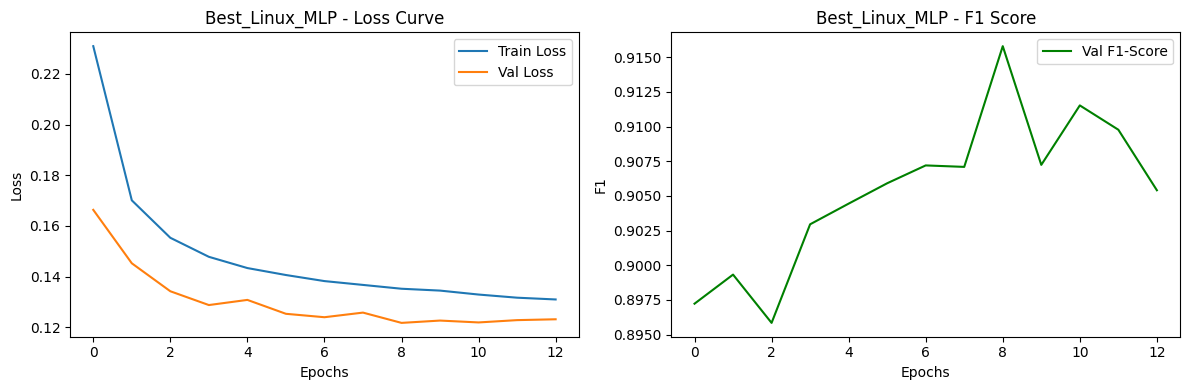

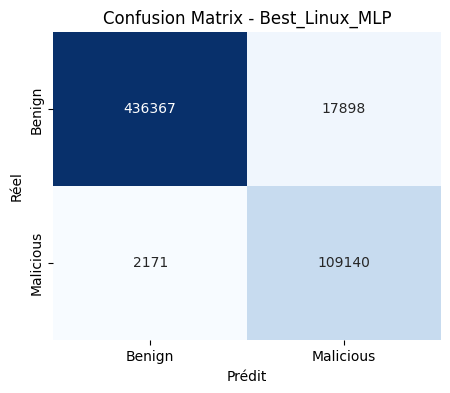

-> Résultat : F1=0.9158 | Recall=0.9805 | 71.8 KB
------------------------------------------------------------

>>> Entraînement : Best_Linux_CNN (Features: 39)

[START] Entraînement : Best_Linux_CNN
Epoch 1/20 | Loss: 0.4812 | Val Loss: 0.3123 | Val F1: 0.7893
Epoch 2/20 | Loss: 0.3574 | Val Loss: 0.2825 | Val F1: 0.7981
Epoch 3/20 | Loss: 0.3282 | Val Loss: 0.3193 | Val F1: 0.8758
Epoch 4/20 | Loss: 0.3133 | Val Loss: 1.8167 | Val F1: 0.2271
Epoch 5/20 | Loss: 0.3026 | Val Loss: 0.2487 | Val F1: 0.8731
Epoch 6/20 | Loss: 0.2945 | Val Loss: 0.3306 | Val F1: 0.8831
Epoch 7/20 | Loss: 0.2876 | Val Loss: 0.2996 | Val F1: 0.8882
Epoch 8/20 | Loss: 0.2837 | Val Loss: 0.2773 | Val F1: 0.8870
Epoch 9/20 | Loss: 0.2794 | Val Loss: 0.5470 | Val F1: 0.7431
Epoch 10/20 | Loss: 0.2752 | Val Loss: 0.2716 | Val F1: 0.8973
Epoch 11/20 | Loss: 0.2711 | Val Loss: 0.2849 | Val F1: 0.8984
Epoch 12/20 | Loss: 0.2687 | Val Loss: 0.4101 | Val F1: 0.7981
Epoch 13/20 | Loss: 0.2667 | Val Loss: 0.3606 | Val F

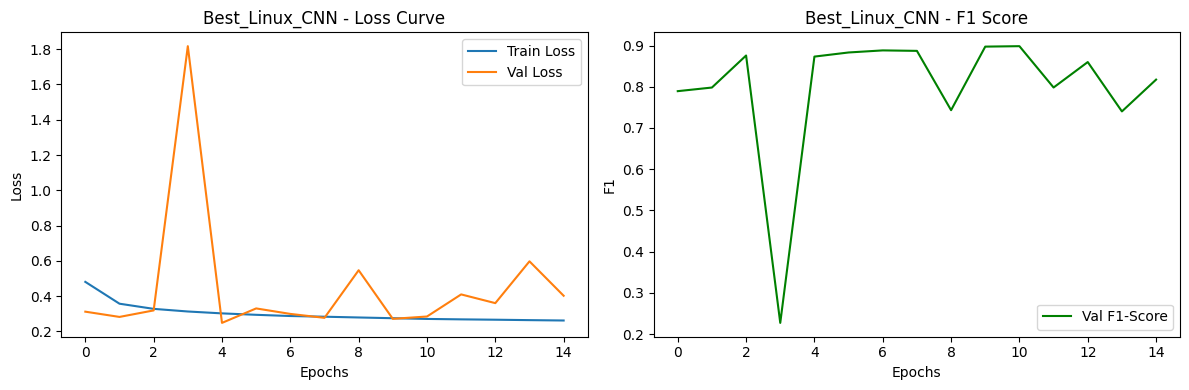

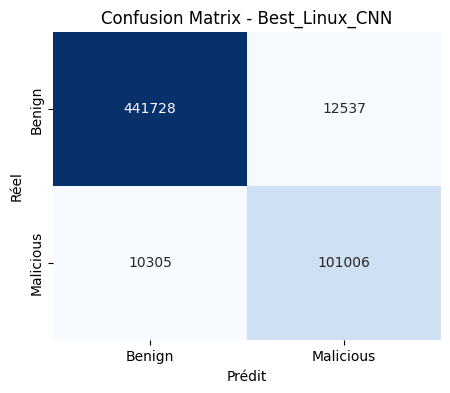

-> Résultat : F1=0.8984 | Recall=0.9074 | 32.4 KB
------------------------------------------------------------

>>> Entraînement : Best_Linux_Attn (Features: 39)

[START] Entraînement : Best_Linux_Attn
Epoch 1/20 | Loss: 0.3005 | Val Loss: 0.2429 | Val F1: 0.8613
Epoch 2/20 | Loss: 0.2389 | Val Loss: 0.2254 | Val F1: 0.8707
Epoch 3/20 | Loss: 0.2190 | Val Loss: 0.2110 | Val F1: 0.8763
Epoch 4/20 | Loss: 0.2089 | Val Loss: 0.2091 | Val F1: 0.8757
Epoch 5/20 | Loss: 0.2010 | Val Loss: 0.1929 | Val F1: 0.8856
Epoch 6/20 | Loss: 0.1939 | Val Loss: 0.1928 | Val F1: 0.9090
Epoch 7/20 | Loss: 0.1872 | Val Loss: 0.1725 | Val F1: 0.8852
Epoch 8/20 | Loss: 0.1800 | Val Loss: 0.1706 | Val F1: 0.8813
Epoch 9/20 | Loss: 0.1736 | Val Loss: 0.1585 | Val F1: 0.9060
Epoch 10/20 | Loss: 0.1685 | Val Loss: 0.1643 | Val F1: 0.9046
[STOP] Early Stopping déclenché à l'époque 10
[FIN] Durée: 271s | Best Val F1: 0.9090


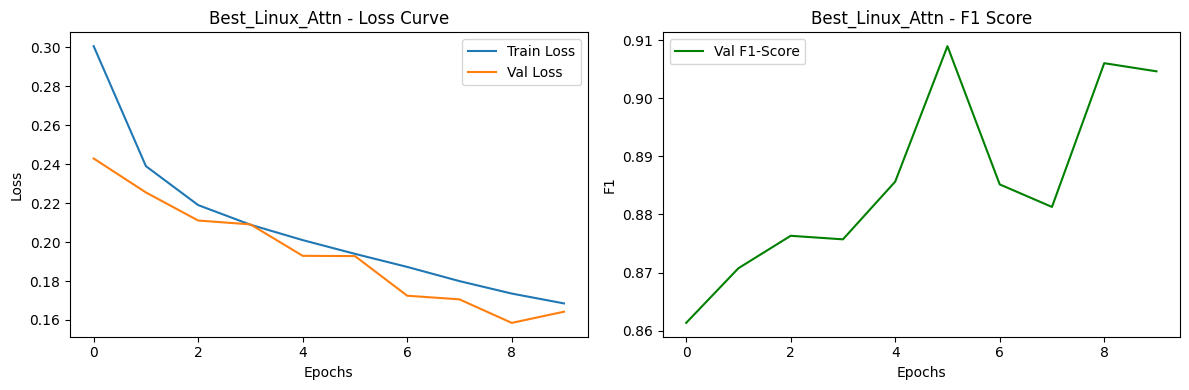

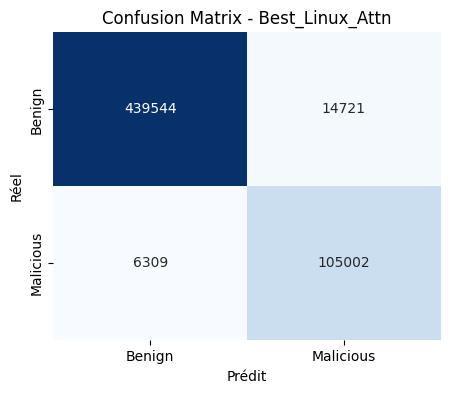

-> Résultat : F1=0.9090 | Recall=0.9433 | 26.2 KB
------------------------------------------------------------

>>> Entraînement : Best_Pi_MLP (Features: 18)

[START] Entraînement : Best_Pi_MLP
Epoch 1/20 | Loss: 0.3617 | Val Loss: 0.2736 | Val F1: 0.7965
Epoch 2/20 | Loss: 0.2794 | Val Loss: 0.3026 | Val F1: 0.7835
Epoch 3/20 | Loss: 0.2412 | Val Loss: 0.2768 | Val F1: 0.8660
Epoch 4/20 | Loss: 0.2169 | Val Loss: 0.2989 | Val F1: 0.8240
Epoch 5/20 | Loss: 0.2043 | Val Loss: 0.3116 | Val F1: 0.8077
Epoch 6/20 | Loss: 0.1936 | Val Loss: 0.1462 | Val F1: 0.9124
Epoch 7/20 | Loss: 0.1800 | Val Loss: 0.3591 | Val F1: 0.7762
Epoch 8/20 | Loss: 0.1771 | Val Loss: 0.3717 | Val F1: 0.8348
Epoch 9/20 | Loss: 0.1677 | Val Loss: 0.1273 | Val F1: 0.9189
Epoch 10/20 | Loss: 0.1674 | Val Loss: 0.1415 | Val F1: 0.9132
Epoch 11/20 | Loss: 0.1634 | Val Loss: 0.1266 | Val F1: 0.9098
Epoch 12/20 | Loss: 0.1621 | Val Loss: 0.2604 | Val F1: 0.8421
Epoch 13/20 | Loss: 0.1586 | Val Loss: 0.4918 | Val F1: 0.7

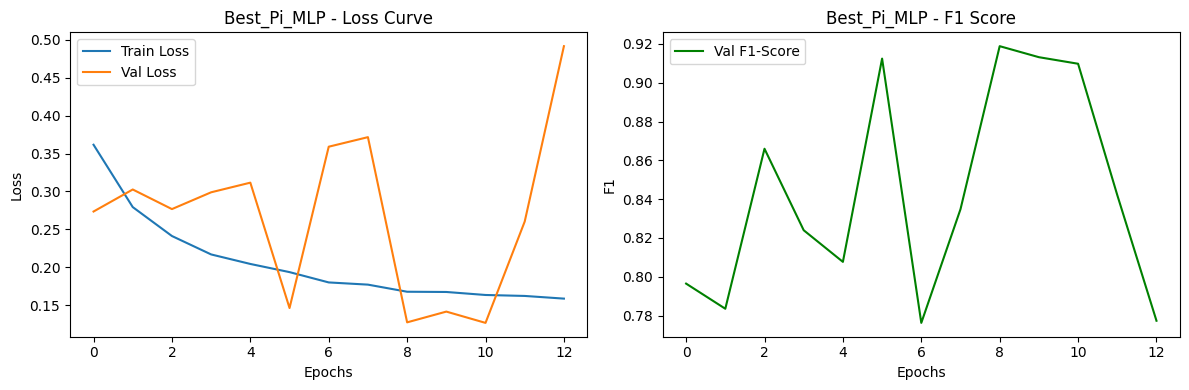

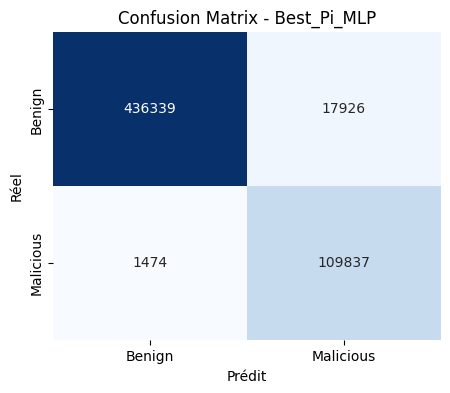

-> Résultat : F1=0.9189 | Recall=0.9868 | 61.2 KB
------------------------------------------------------------

>>> Entraînement : Best_Pi_CNN (Features: 18)

[START] Entraînement : Best_Pi_CNN
Epoch 1/20 | Loss: 0.4907 | Val Loss: 0.3837 | Val F1: 0.6760
Epoch 2/20 | Loss: 0.4143 | Val Loss: 0.6805 | Val F1: 0.7339
Epoch 3/20 | Loss: 0.4012 | Val Loss: 0.4119 | Val F1: 0.7852
Epoch 4/20 | Loss: 0.3943 | Val Loss: 0.3619 | Val F1: 0.7997
Epoch 5/20 | Loss: 0.3893 | Val Loss: 0.5249 | Val F1: 0.7887
Epoch 6/20 | Loss: 0.3849 | Val Loss: 0.3991 | Val F1: 0.7879
Epoch 7/20 | Loss: 0.3820 | Val Loss: 0.3913 | Val F1: 0.7879
Epoch 8/20 | Loss: 0.3790 | Val Loss: 0.3675 | Val F1: 0.7869
[STOP] Early Stopping déclenché à l'époque 8
[FIN] Durée: 153s | Best Val F1: 0.7997


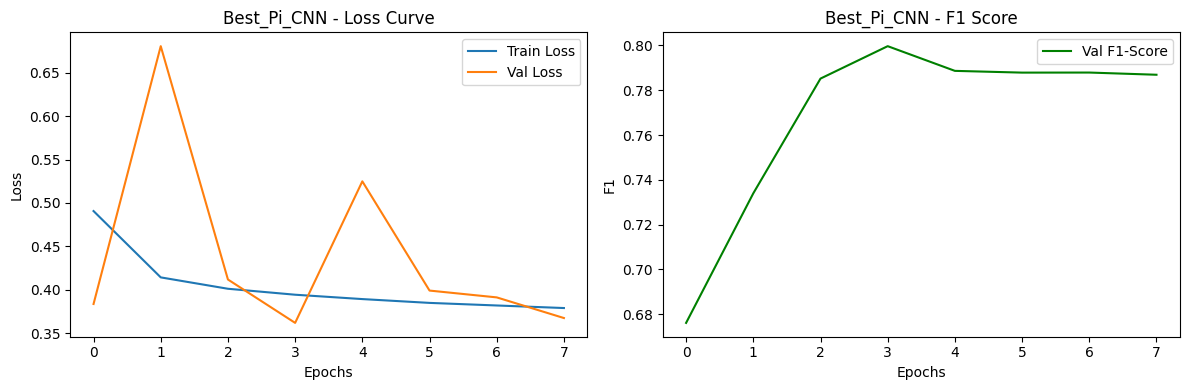

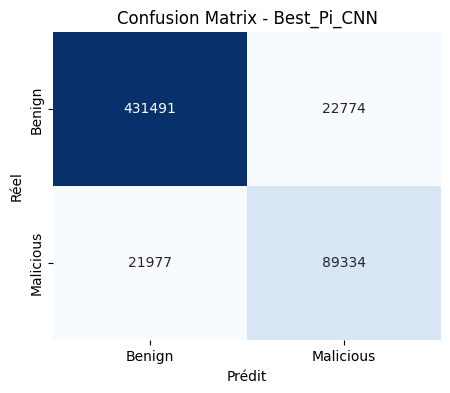

-> Résultat : F1=0.7997 | Recall=0.8026 | 32.3 KB
------------------------------------------------------------

>>> Entraînement : Best_Pi_Attn (Features: 18)

[START] Entraînement : Best_Pi_Attn
Epoch 1/20 | Loss: 0.4164 | Val Loss: 0.3299 | Val F1: 0.8023
Epoch 2/20 | Loss: 0.3292 | Val Loss: 0.2977 | Val F1: 0.8171
Epoch 3/20 | Loss: 0.2992 | Val Loss: 0.2937 | Val F1: 0.8304
Epoch 4/20 | Loss: 0.2930 | Val Loss: 0.2974 | Val F1: 0.8378
Epoch 5/20 | Loss: 0.2904 | Val Loss: 0.2775 | Val F1: 0.8348
Epoch 6/20 | Loss: 0.2852 | Val Loss: 0.2729 | Val F1: 0.8469
Epoch 7/20 | Loss: 0.2830 | Val Loss: 0.2818 | Val F1: 0.8464
Epoch 8/20 | Loss: 0.2807 | Val Loss: 0.2780 | Val F1: 0.8510
Epoch 9/20 | Loss: 0.2776 | Val Loss: 0.2744 | Val F1: 0.8446
Epoch 10/20 | Loss: 0.2736 | Val Loss: 0.2802 | Val F1: 0.8313
Epoch 11/20 | Loss: 0.2713 | Val Loss: 0.2598 | Val F1: 0.8443
Epoch 12/20 | Loss: 0.2704 | Val Loss: 0.2603 | Val F1: 0.8552
Epoch 13/20 | Loss: 0.2675 | Val Loss: 0.2394 | Val F1: 0

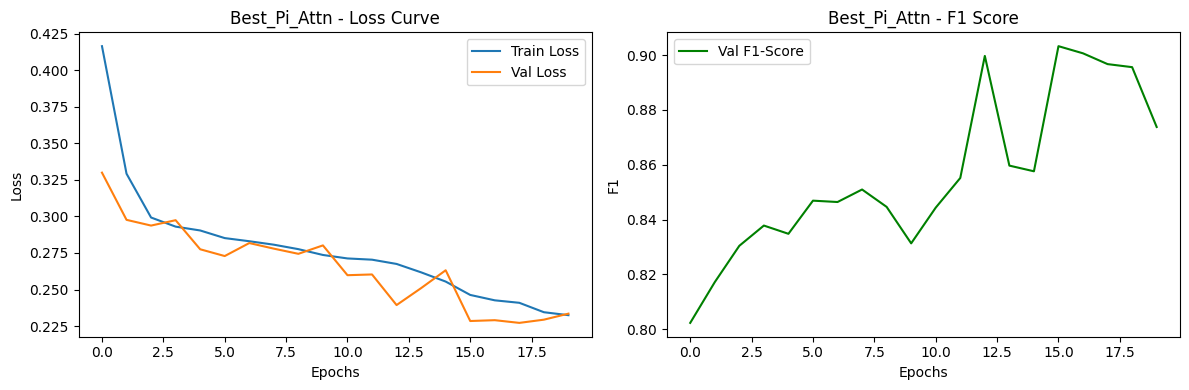

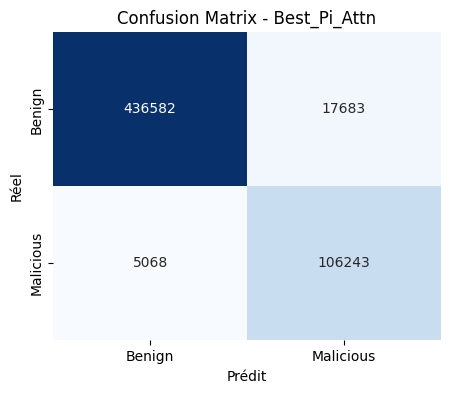

-> Résultat : F1=0.9033 | Recall=0.9545 | 23.5 KB
------------------------------------------------------------

=== 🏆 TABLEAU COMPARATIF FINAL ===


,Platform,Arch,Accuracy,F1-Score,Precision,Recall,Inference (µs),Size (KB),Train Time (s)
0,Linux,MLP,0.9645,0.9158,0.8591,0.9805,0.35,71.8,306.3
1,Linux,CNN,0.9596,0.8984,0.8896,0.9074,0.25,32.4,357.0
2,Linux,Attn,0.9628,0.9090,0.8770,0.9433,0.27,26.2,271.3
3,Pi,MLP,0.9657,0.9189,0.8597,0.9868,0.28,61.2,236.8
4,Pi,CNN,0.9209,0.7997,0.7969,0.8026,0.25,32.3,153.2
5,Pi,Attn,0.9598,0.9033,0.8573,0.9545,0.29,23.5,386.7


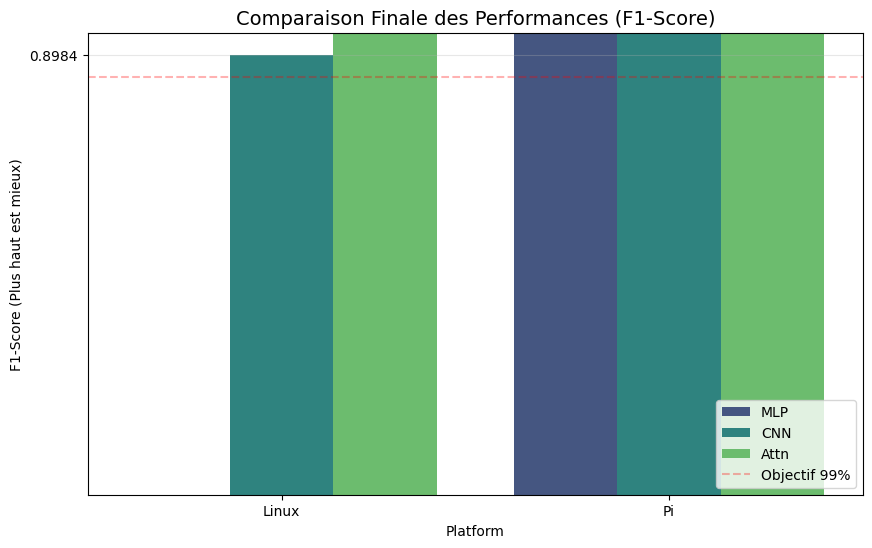

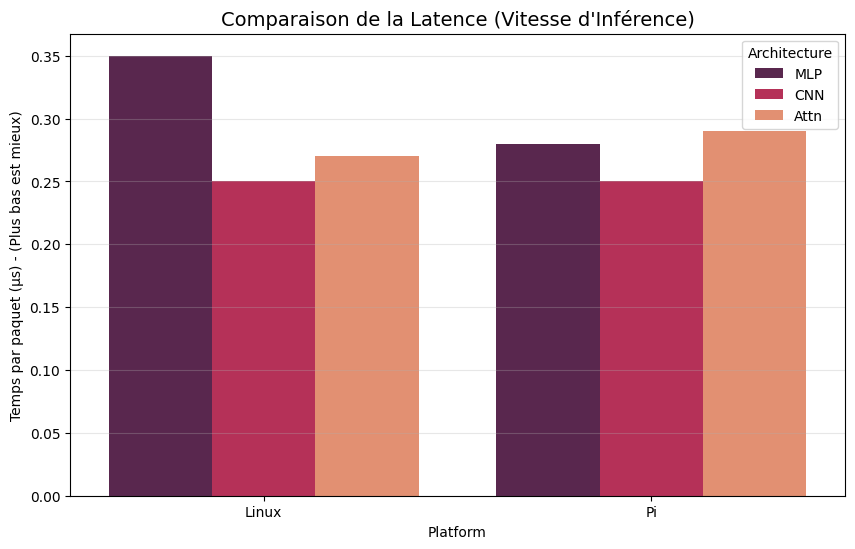

✅ Benchmarks terminés. Résultats sauvegardés dans 'models/benchmark_results.csv'.


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, accuracy_score

# Liste pour stocker les résultats
results_log = []

# Configuration des expériences
# Format: (Platform, Architecture, Class, TrainL, TestL, PosWeight, InputDim)
experiments = [
    # --- LINUX (Serveur) ---
    ('Linux', 'MLP', IDS_MLP, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features'])),
    ('Linux', 'CNN', IDS_CNN, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features'])),
    ('Linux', 'Attn', IDS_Attention, train_loader_l, test_loader_l, pos_weight_l, len(data_linux['features'])),
    
    # --- RASPBERRY PI (Edge) ---
    ('Pi', 'MLP', IDS_MLP, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features'])),
    ('Pi', 'CNN', IDS_CNN, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features'])),
    ('Pi', 'Attn', IDS_Attention, train_loader_p, test_loader_p, pos_weight_p, len(data_pi['features'])),
]

print(f"🚀 DÉMARRAGE DU BENCHMARK COMPLET SUR {DEVICE}...")
print("="*80)

for platform, arch, model_cls, t_loader, v_loader, p_weight, in_dim in experiments:
    model_name = f"Best_{platform}_{arch}"
    print(f"\n>>> Entraînement : {model_name} (Features: {in_dim})")
    
    # 1. Instanciation
    model = model_cls(input_dim=in_dim)
    
    # 2. Entraînement (Epochs=20 pour convergence max, EarlyStopping veille au grain)
    trained_model, history, train_time = train_model(
        model, t_loader, v_loader, p_weight, 
        epochs=20, patience=4, model_name=model_name
    )
    
    # --- VISUALISATION 1 : COURBES D'APPRENTISSAGE (Task 5.4) ---
    plt.figure(figsize=(12, 4))
    
    # Courbe de Loss
    plt.subplot(1, 2, 1)
    plt.plot(history['train_loss'], label='Train Loss')
    plt.plot(history['val_loss'], label='Val Loss')
    plt.title(f'{model_name} - Loss Curve')
    plt.xlabel('Epochs')
    plt.ylabel('Loss')
    plt.legend()
    
    # Courbe de F1-Score
    plt.subplot(1, 2, 2)
    plt.plot(history['val_f1'], label='Val F1-Score', color='green')
    plt.title(f'{model_name} - F1 Score')
    plt.xlabel('Epochs')
    plt.ylabel('F1')
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    # 3. Évaluation Technique
    trained_model.eval()
    
    # A. Taille & Latence
    model_path = f"models/{model_name}.pth"
    size_kb = os.path.getsize(model_path) / 1024
    
    # Mesure Latence (Moyenne sur 100 pass)
    sample_input, _ = next(iter(v_loader))
    sample_input = sample_input.to(DEVICE)
    start_inf = time.time()
    with torch.no_grad():
        for _ in range(100): # Warmup & Avg
            _ = trained_model(sample_input)
    end_inf = time.time()
    inference_time_us = ((end_inf - start_inf) / (100 * sample_input.size(0))) * 1_000_000
    
    # 4. Métriques Complètes
    y_true = []
    y_pred = []
    with torch.no_grad():
        for inputs, labels in v_loader:
            inputs = inputs.to(DEVICE)
            outputs = trained_model(inputs)
            preds = (torch.sigmoid(outputs) > 0.5).cpu().numpy()
            y_true.extend(labels.numpy())
            y_pred.extend(preds)
            
    f1 = f1_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred)
    rec = recall_score(y_true, y_pred)
    acc = accuracy_score(y_true, y_pred)
    
    # --- VISUALISATION 2 : MATRICE DE CONFUSION (Task 6.1) ---
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Benign', 'Malicious'], yticklabels=['Benign', 'Malicious'])
    plt.title(f"Confusion Matrix - {model_name}")
    plt.ylabel('Réel')
    plt.xlabel('Prédit')
    plt.show()
    
    # Log
    results_log.append({
        'Platform': platform,
        'Arch': arch,
        'Accuracy': f"{acc:.4f}",
        'F1-Score': f"{f1:.4f}",
        'Precision': f"{prec:.4f}",
        'Recall': f"{rec:.4f}",
        'Inference (µs)': round(inference_time_us, 2),
        'Size (KB)': round(size_kb, 1),
        'Train Time (s)': round(train_time, 1)
    })
    
    print(f"-> Résultat : F1={f1:.4f} | Recall={rec:.4f} | {size_kb:.1f} KB")
    print("-" * 60)

# ==========================================
# TABLEAU FINAL
# ==========================================
# 1. Tableau des Résultats
print("\n=== 🏆 TABLEAU COMPARATIF FINAL ===")
# On affiche tout sauf les colonnes trop larges si besoin, ou tout le DF
df_results = pd.DataFrame(results_log)
display(df_results)
df_results.to_csv("models/benchmark_results.csv", index=False)

# 2. Graphique Comparatif (F1-Score)
plt.figure(figsize=(10, 6))
sns.barplot(data=df_results, x='Platform', y='F1-Score', hue='Arch', palette='viridis')
plt.title("Comparaison Finale des Performances (F1-Score)", fontsize=14)
plt.ylabel("F1-Score (Plus haut est mieux)")
plt.ylim(0.80, 1.01) # Zoom pour voir les différences subtiles entre modèles performants
plt.axhline(y=0.99, color='r', linestyle='--', alpha=0.3, label='Objectif 99%')
plt.legend(loc='lower right')
plt.grid(axis='y', alpha=0.3)
plt.show()

# 3. Graphique Comparatif (Latence / Vitesse)
# Convertir la colonne Inference en float si ce n'est pas déjà fait
df_results['Inference (µs)'] = df_results['Inference (µs)'].astype(float)

plt.figure(figsize=(10, 6))
sns.barplot(data=df_results, x='Platform', y='Inference (µs)', hue='Arch', palette='rocket')
plt.title("Comparaison de la Latence (Vitesse d'Inférence)", fontsize=14)
plt.ylabel("Temps par paquet (µs) - (Plus bas est mieux)")
plt.legend(title='Architecture')
plt.grid(axis='y', alpha=0.3)
plt.show()

print("✅ Benchmarks terminés. Résultats sauvegardés dans 'models/benchmark_results.csv'.")


In [ ]:
import joblib
import sys
import time

# ==========================================
# 1. PRÉPARATION DE LA SIMULATION (REALISTE)
# ==========================================

# CORRECTION : On utilise X_test_p (NON SCALÉ) qui est encore en mémoire depuis la Task 4.
# Cela simule de vraies valeurs brutes (ex: Port 80, Length 1500) et non des 0.123
X_sim = X_test_p.copy().reset_index(drop=True)
y_sim = y_test_p.reset_index(drop=True)

# Sélection de 20 paquets mixés (10 Benign / 10 Malicious)
indices_benign = y_sim[y_sim == 0].index[:10]
indices_malic = y_sim[y_sim == 1].index[:10]
indices_mix = np.concatenate([indices_benign, indices_malic])
np.random.shuffle(indices_mix) 

# Création du CSV de simulation "RAW"
df_sim = X_sim.iloc[indices_mix].copy()
true_labels = y_sim.iloc[indices_mix]

df_sim.to_csv("datasets/sim_network.csv", index=False)
print("[INFO] Fichier 'datasets/sim_network.csv' généré avec des DONNÉES BRUTES.")

# ==========================================
# 2. CHARGEMENT DU MOTEUR
# ==========================================

# Chargement du Scaler (Indispensable pour traiter les données brutes)
try:
    scaler_deployment = joblib.load('models/scaler_pi.pkl')
    print("[INFO] Scaler 'scaler_pi.pkl' chargé.")
except:
    print("[WARN] Fichier scaler introuvable. Utilisation de la variable mémoire.")
    scaler_deployment = scaler_p

# Chargement du Modèle
# On prend le MLP car c'est le plus adapté pour le Pi (Rapide)
model_deployment = IDS_MLP(input_dim=len(features_pi))
try:
    model_deployment.load_state_dict(torch.load('models/Best_Pi_MLP.pth', map_location=DEVICE))
    print("[INFO] Modèle 'Best_Pi_MLP' chargé.")
except:
    print("[ERREUR] Modèle introuvable, assurez-vous d'avoir fini la Task 5.")

model_deployment.to(DEVICE)
model_deployment.eval()

# ==========================================
# 3. BOUCLE D'INFÉRENCE TEMPS RÉEL
# ==========================================

print("\n" + "="*60)
print("   🛡️  NIDS SENTINEL - RASPBERRY PI MODE ACTIVATED")
print("="*60 + "\n")

GREEN = '\033[92m'
RED = '\033[91m'
RESET = '\033[0m'

print("Listening on interface eth0...\n")
time.sleep(1)

for i in range(len(df_sim)):
    # A. Capture (Ligne CSV brute)
    packet_raw = df_sim.iloc[[i]] 
    
    # B. Preprocessing (LE TEST ULTIME : SCALING EN TEMPS RÉEL)
    # C'est ici qu'on vérifie si le scaler marche sur une seule ligne
    try:
        packet_scaled = scaler_deployment.transform(packet_raw)
        packet_tensor = torch.tensor(packet_scaled, dtype=torch.float32).to(DEVICE)
    except Exception as e:
        print(f"[ERR] Erreur de scaling : {e}")
        continue

    # C. Inférence
    start_t = time.time()
    with torch.no_grad():
        logits = model_deployment(packet_tensor)
        probs = torch.sigmoid(logits).item()
    inference_time = (time.time() - start_t) * 1000 # ms
    
    # D. Décision
    is_attack = probs > 0.5
    confidence = probs if is_attack else 1 - probs
    
    # E. Affichage
    time.sleep(0.1) # Effet visuel
    
    status = f"{RED}[ALERT!]{RESET}" if is_attack else f"{GREEN}[SAFE]{RESET}"
    attack_label = "DoS/Attack" if is_attack else "Benign"
    
    # Récupération d'infos pour l'affichage (depuis les données brutes !)
    pkt_len = packet_raw['Total Length of Fwd Packets'].values[0]
    
    sys.stdout.write(f"\rpkt_{i+1:02d} | Len:{pkt_len:4.0f} | {status} | Conf: {confidence:.0%} | {inference_time:.2f}ms")
    sys.stdout.flush()
    
    if is_attack:
        print(f"\n      >>> 🚫 BLOCKING TRAFFIC (Confidence: {confidence:.2f})")
        time.sleep(0.5)

print("\n\n" + "="*60)
print("SIMULATION TERMINÉE.")